In [1]:
from google.colab import drive
drive.mount('/content/drive')
%cd /content/drive/MyDrive/simuteh-2330511026/notebook

Mounted at /content/drive
/content/drive/MyDrive/simuteh-2330511026/notebook


In [2]:
import os
print("Folder kerja :", os.getcwd())
print("Isi folder   :", os.listdir("."))
print("Ada ../src ? :", os.path.exists("../src"))
if os.path.exists("../src"):
    print("Isi ../src   :", os.listdir("../src"))

Folder kerja : /content/drive/MyDrive/simuteh-2330511026/notebook
Isi folder   : ['B2_citra_warna.ipynb', 'B3_histogram.ipynb', 'B4_penapisan.ipynb', 'B1_lingkungan.ipynb', 'B5_praproses.ipynb', 'P6_morfologi.ipynb', 'P5_tepi.ipynb']
Ada ../src ? : True
Isi ../src   : ['__pycache__', 'praproses.py', 'utils_tepi.py', 'utils_cv.py', 'bercak.py']


Kode 1.1 Persiapan: modul, data, praproses, dan tepi acuan

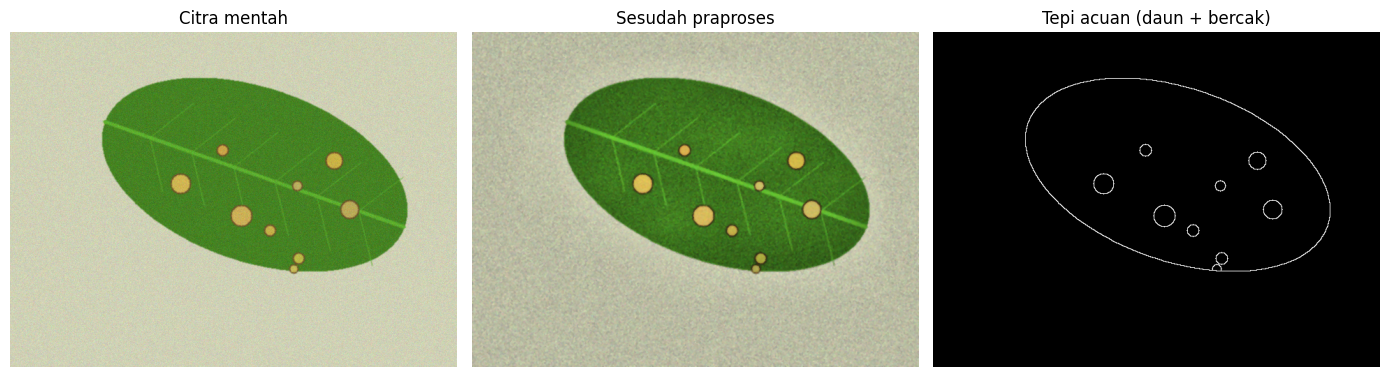

In [3]:
import sys, json
sys.path.insert(0, "/content/drive/MyDrive/simuteh-2330511026/src")

import cv2, numpy as np, pandas as pd, matplotlib.pyplot as plt
from utils_cv import baca, tampil
from praproses import praproses
from utils_tepi import tepi_acuan, skor_tepi, iou, mask_daun_awal, bercak_awal

pd.set_option("display.width", 160)
pd.set_option("display.max_columns", 20)

PARAM = json.load(open("../hasil/param_praproses.json"))  # hasil Evaluasi P1-P4
label = pd.read_csv("../data/sintetis/label.csv")


def muat(nama):
    img = baca(f"../data/sintetis/citra/{nama}")
    md = cv2.imread(f"../data/sintetis/mask_daun/{nama}", 0)
    mb = cv2.imread(f"../data/sintetis/mask_bercak/{nama}", 0)
    return img, md, mb


img, md, mb = muat("teh_041.png")
pra = praproses(img, PARAM)

acuan = cv2.bitwise_or(tepi_acuan(md), tepi_acuan(mb))
tampil([img, pra, acuan],
       ["Citra mentah", "Sesudah praproses", "Tepi acuan (daun + bercak)"])

Kode 1.2 Gradien Sobel manual: Gx, Gy, magnitudo, dan arah

selisih maks gx manual vs cv2.Sobel: 0.0
magnitudo maks: 603.2


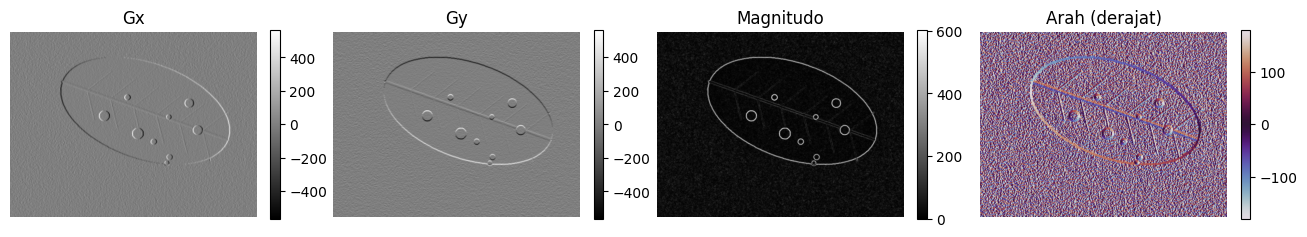

In [4]:
g = pra[:, :, 2].astype(np.float32)  # kanal R hasil praproses

kx = np.array([[-1, 0, 1], [-2, 0, 2], [-1, 0, 1]], np.float32)
ky = kx.T

gx = cv2.filter2D(g, cv2.CV_32F, kx)  # turunan arah x (tepi vertikal)
gy = cv2.filter2D(g, cv2.CV_32F, ky)  # turunan arah y (tepi horizontal)
mag = np.sqrt(gx ** 2 + gy ** 2)
arah = np.degrees(np.arctan2(gy, gx))

# bandingkan dengan fungsi pustaka
gx_cv = cv2.Sobel(g, cv2.CV_32F, 1, 0, ksize=3)
print("selisih maks gx manual vs cv2.Sobel:", np.abs(gx - gx_cv).max())
print("magnitudo maks:", mag.max().round(1))

plt.figure(figsize=(16, 3.6))
for i, (c, jd) in enumerate([(gx, "Gx"), (gy, "Gy"),
                             (mag, "Magnitudo"), (arah, "Arah (derajat)")]):
    plt.subplot(1, 4, i + 1)
    plt.imshow(c, cmap="twilight" if i == 3 else "gray")
    plt.title(jd)
    plt.axis("off")
    plt.colorbar(fraction=0.035)

Kode 1.3 Fungsi Sobel, Prewitt, LoG, dan Canny serta perbandingannya

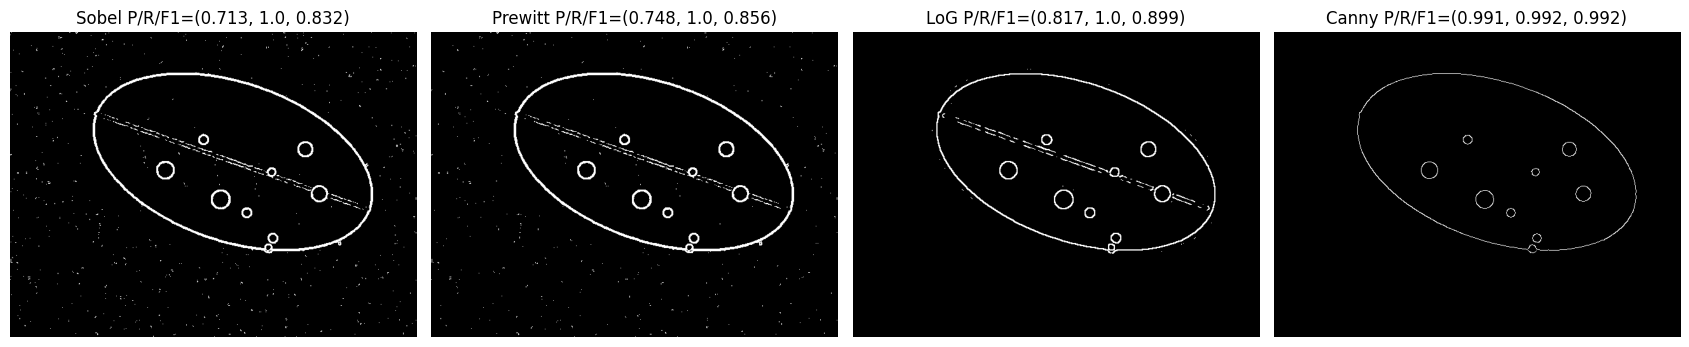

In [5]:
def tepi_sobel(g, T=100):
    g = g.astype(np.float32)
    m = np.hypot(cv2.Sobel(g, cv2.CV_32F, 1, 0), cv2.Sobel(g, cv2.CV_32F, 0, 1))
    return ((m > T) * 255).astype(np.uint8)


def tepi_prewitt(g, T=75):
    kx = np.array([[-1, 0, 1], [-1, 0, 1], [-1, 0, 1]], np.float32)
    g = g.astype(np.float32)
    m = np.hypot(cv2.filter2D(g, -1, kx), cv2.filter2D(g, -1, kx.T))
    return ((m > T) * 255).astype(np.uint8)


def tepi_log(g, sigma=3.0, frac=0.2):
    """Laplacian of Gaussian: tepi = perlintasan nol yang cukup kuat."""
    L = cv2.Laplacian(cv2.GaussianBlur(g.astype(np.float32), (0, 0), sigma), cv2.CV_32F)
    mn, mx = cv2.erode(L, np.ones((3, 3))), cv2.dilate(L, np.ones((3, 3)))
    return (((mn < 0) & (mx > 0) & (mx - mn > frac * np.abs(L).max())) * 255).astype(np.uint8)


def tepi_canny(g, lo=30, hi=90, sigma=2.0):
    if sigma > 0:
        g = cv2.GaussianBlur(g, (0, 0), sigma)
    return cv2.Canny(g, lo, hi)


metode = {"Sobel": tepi_sobel, "Prewitt": tepi_prewitt, "LoG": tepi_log, "Canny": tepi_canny}

g = pra[:, :, 2]
hasil = {nm: f(g) for nm, f in metode.items()}
tampil(list(hasil.values()),
       [f"{nm} P/R/F1={skor_tepi(e, acuan)}" for nm, e in hasil.items()],
       ukuran=(17, 3.6))

Kode 1.4 Tabel presisi, recall, dan F1 tepi

In [6]:
baris = []
for _, d in label[label.kelas != "sehat"].iterrows():
    img, md, mb = muat(d.nama_file)
    ac = cv2.bitwise_or(tepi_acuan(md), tepi_acuan(mb))
    for sumber, im in [("mentah", img), ("praproses", praproses(img, PARAM))]:
        for kanal, g in [("Gray", cv2.cvtColor(im, cv2.COLOR_BGR2GRAY)),
                         ("R", im[:, :, 2])]:
            for nm, f in metode.items():
                p, r, f1 = skor_tepi(f(g), ac)
                baris.append([d.kondisi_cahaya, sumber, kanal, nm, p, r, f1])

tabel_tepi = pd.DataFrame(baris, columns=["kondisi", "sumber", "kanal", "metode", "P", "R", "F1"])
ringkas = tabel_tepi.groupby(["sumber", "kanal", "metode"])[["P", "R", "F1"]].mean().round(3)
print(ringkas)
tabel_tepi.to_csv("../hasil/p5_tabel_tepi.csv", index=False)

                             P      R     F1
sumber    kanal metode                      
mentah    Gray  Canny    0.780  0.768  0.772
                LoG      0.640  0.997  0.776
                Prewitt  0.777  0.971  0.856
                Sobel    0.738  0.975  0.830
          R     Canny    0.989  0.987  0.988
                LoG      0.904  0.998  0.945
                Prewitt  0.527  0.997  0.640
                Sobel    0.462  0.997  0.577
praproses Gray  Canny    0.695  0.951  0.796
                LoG      0.560  0.997  0.710
                Prewitt  0.538  0.997  0.687
                Sobel    0.502  0.997  0.654
          R     Canny    0.947  0.992  0.966
                LoG      0.840  0.998  0.903
                Prewitt  0.459  0.998  0.596
                Sobel    0.412  0.998  0.549


grafik

metode          Sobel  Prewitt    LoG  Canny
kondisi                                     
normal          0.538    0.584  0.947  0.933
gelap           0.614    0.663  0.980  0.980
terang          0.535    0.590  0.886  0.960
kontras_rendah  0.576    0.619  0.801  0.981
bayangan        0.480    0.526  0.903  0.975


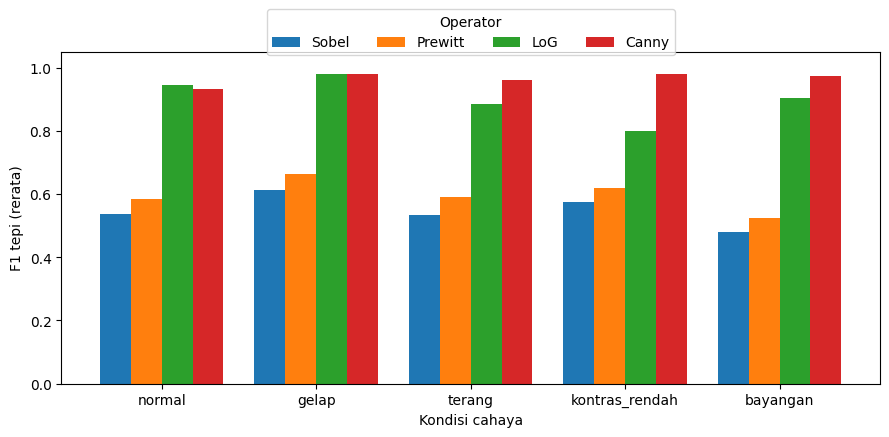

In [7]:
# F1 per kondisi cahaya: kanal R, sesudah praproses
sub = tabel_tepi[(tabel_tepi.sumber == "praproses") & (tabel_tepi.kanal == "R")]

pv = sub.pivot_table(index="kondisi", columns="metode", values="F1", aggfunc="mean")
pv = pv.reindex(["normal", "gelap", "terang", "kontras_rendah", "bayangan"])[
    ["Sobel", "Prewitt", "LoG", "Canny"]]
print(pv.round(3))

ax = pv.plot(kind="bar", figsize=(9, 4.5), width=0.8)
ax.set_ylabel("F1 tepi (rerata)")
ax.set_xlabel("Kondisi cahaya")
ax.set_ylim(0, 1.05)
plt.xticks(rotation=0)
plt.legend(title="Operator", ncol=4, loc="upper center", bbox_to_anchor=(0.5, 1.15))
plt.tight_layout()
plt.savefig("../hasil/p5_f1_kondisi.png", dpi=150)
plt.show()

Kode 2.1 Eksperimen sigma dan ambang Canny

In [8]:
baris = []
for _, d in label[label.kelas != "sehat"].iterrows():
    img, md, mb = muat(d.nama_file)
    g = praproses(img, PARAM)[:, :, 2]
    ad, ab = tepi_acuan(md), tepi_acuan(mb)
    ac = cv2.bitwise_or(ad, ab)
    for sigma in [0, 1.0, 2.0]:
        for lo, hi in [(30, 90), (50, 150), (100, 200)]:
            e = tepi_canny(g, lo, hi, sigma)
            p, r, f1 = skor_tepi(e, ac)
            r_bercak = skor_tepi(e, ab)[1]  # recall khusus tepi bercak
            baris.append([d.kelas, sigma, f"{lo}/{hi}", p, r, f1, r_bercak])

canny = pd.DataFrame(baris, columns=["kelas", "sigma", "ambang", "P", "R", "F1", "R_bercak"])
print(canny.groupby(["sigma", "ambang"])[["P", "R", "F1", "R_bercak"]].mean().round(3))
print(canny.pivot_table(index=["sigma", "ambang"], columns="kelas",
                        values="R_bercak").round(3))

                   P      R     F1  R_bercak
sigma ambang                                
0.0   100/200  0.519  0.995  0.633     0.982
      30/90    0.019  0.998  0.037     0.994
      50/150   0.103  0.996  0.166     0.986
1.0   100/200  0.979  0.995  0.987     0.977
      30/90    0.226  0.996  0.320     0.980
      50/150   0.882  0.995  0.931     0.979
2.0   100/200  0.844  0.831  0.837     0.742
      30/90    0.947  0.992  0.966     0.955
      50/150   0.984  0.984  0.984     0.864
kelas          berat  ringan
sigma ambang                
0.0   100/200  0.982   0.982
      30/90    0.993   0.996
      50/150   0.986   0.987
1.0   100/200  0.979   0.976
      30/90    0.983   0.976
      50/150   0.982   0.976
2.0   100/200  0.766   0.716
      30/90    0.966   0.944
      50/150   0.946   0.781


Kode 2.2 Ambang Canny otomatis berbasis median

In [9]:
def canny_otomatis(g, s=0.33):
    """Ambang dari median intensitas: bawah = (1-s) x median, atas = (1+s) x median."""
    v = np.median(g)
    return cv2.Canny(g, int(max(0, (1 - s) * v)), int(min(255, (1 + s) * v)))


baris = []
for _, d in label[label.kelas != "sehat"].iterrows():
    img, md, mb = muat(d.nama_file)
    ac = cv2.bitwise_or(tepi_acuan(md), tepi_acuan(mb))
    pra_ = praproses(img, PARAM)
    for kanal, g in [("Gray", cv2.cvtColor(pra_, cv2.COLOR_BGR2GRAY)), ("R", pra_[:, :, 2])]:
        baris.append([d.kondisi_cahaya, kanal, "otomatis",
                      skor_tepi(canny_otomatis(g), ac)[2], np.median(g)])
        baris.append([d.kondisi_cahaya, kanal, "tetap 30/90",
                      skor_tepi(tepi_canny(g), ac)[2], np.median(g)])

auto = pd.DataFrame(baris, columns=["kondisi", "kanal", "ambang", "F1", "median"])
print(auto.pivot_table(index=["kanal", "ambang"], columns="kondisi", values="F1").round(3))
print(auto.groupby(["kanal", "kondisi"])["median"].mean().round(1))

kondisi            bayangan  gelap  kontras_rendah  normal  terang
kanal ambang                                                      
Gray  otomatis        0.370  0.604           0.760   0.744   0.861
      tetap 30/90     0.752  0.734           0.947   0.755   0.789
R     otomatis        0.264  0.668           0.658   0.816   0.956
      tetap 30/90     0.975  0.980           0.981   0.933   0.960
kanal  kondisi       
Gray   bayangan          115.5
       gelap             139.5
       kontras_rendah    149.5
       normal            168.2
       terang            196.6
R      bayangan          118.6
       gelap             144.1
       kontras_rendah    152.5
       normal            176.1
       terang            200.1
Name: median, dtype: float64


bandingkan dengan 2.2


In [10]:
def canny_persentil(g, q, rasio=0.4, sigma=2.0):
    """Canny dengan ambang dari persentil magnitudo gradien (bukan dari intensitas)."""
    gh = cv2.GaussianBlur(g, (0, 0), sigma)                       # (1) haluskan
    gf = gh.astype(np.float32)
    mag = np.hypot(cv2.Sobel(gf, cv2.CV_32F, 1, 0),
                   cv2.Sobel(gf, cv2.CV_32F, 0, 1))               # (2) magnitudo Sobel
    hi = float(np.percentile(mag, q))                             # (3) ambang atas = persentil ke-q
    lo = rasio * hi                                               #     ambang bawah = rasio x ambang atas
    return cv2.Canny(gh, lo, hi, L2gradient=True)                 # (4) panggil Canny


baris = []
for _, d in label[label.kelas != "sehat"].iterrows():
    img, md, mb = muat(d.nama_file)
    ac = cv2.bitwise_or(tepi_acuan(md), tepi_acuan(mb))
    pra_ = praproses(img, PARAM)
    for kanal, g in [("Gray", cv2.cvtColor(pra_, cv2.COLOR_BGR2GRAY)), ("R", pra_[:, :, 2])]:
        for q in [90, 95, 98]:
            baris.append([d.kondisi_cahaya, kanal, f"persentil {q}",
                          skor_tepi(canny_persentil(g, q), ac)[2]])

pers = pd.DataFrame(baris, columns=["kondisi", "kanal", "ambang", "F1"])
gabung = pd.concat([pers, auto[["kondisi", "kanal", "ambang", "F1"]]])
print(gabung.pivot_table(index=["kanal", "ambang"], columns="kondisi", values="F1").round(3))

kondisi             bayangan  gelap  kontras_rendah  normal  terang
kanal ambang                                                       
Gray  otomatis         0.370  0.604           0.760   0.744   0.861
      persentil 90     0.075  0.079           0.070   0.089   0.072
      persentil 95     0.378  0.482           0.298   0.530   0.400
      persentil 98     0.767  0.806           0.811   0.808   0.776
      tetap 30/90      0.752  0.734           0.947   0.755   0.789
R     otomatis         0.264  0.668           0.658   0.816   0.956
      persentil 90     0.078  0.076           0.069   0.085   0.072
      persentil 95     0.299  0.308           0.267   0.505   0.356
      persentil 98     0.974  0.990           0.950   0.992   0.928
      tetap 30/90      0.975  0.980           0.981   0.933   0.960


Kode 2.3 Tepi palsu di bagian dalam daun sehat

kanal            Gray      R
kondisi                     
bayangan        777.2    0.0
gelap           917.8    0.0
kontras_rendah   77.8    1.0
normal          882.8    0.0
terang          874.0  226.5


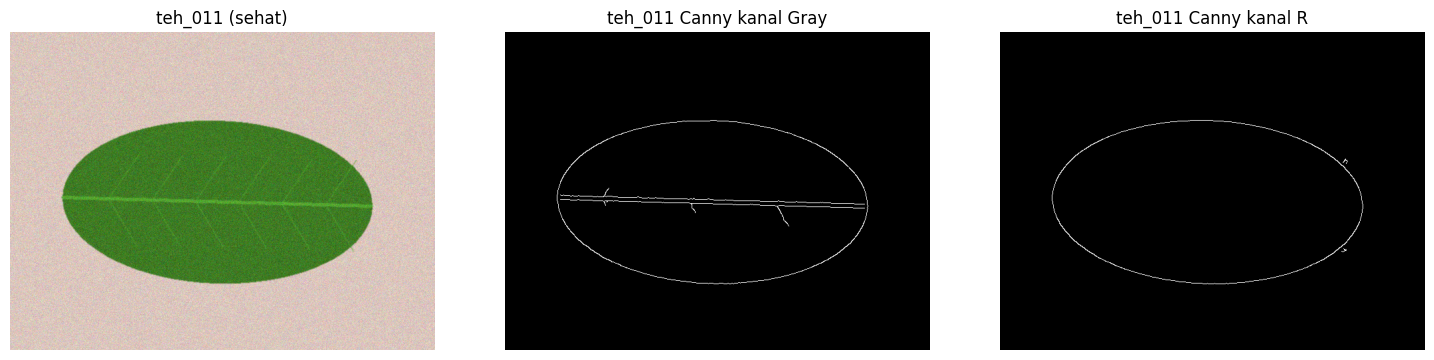

In [11]:
baris, panel, judul = [], [], []
for _, d in label[label.kelas == "sehat"].iterrows():
    img, md, mb = muat(d.nama_file)
    pra_ = praproses(img, PARAM)
    dalam = cv2.erode(md, np.ones((7, 7), np.uint8)) > 0   # bagian dalam daun
    for kanal, g in [("Gray", cv2.cvtColor(pra_, cv2.COLOR_BGR2GRAY)), ("R", pra_[:, :, 2])]:
        e = tepi_canny(g)
        baris.append([d.kondisi_cahaya, kanal, int(((e > 0) & dalam).sum())])
        if d.nama_file == "teh_011.png":
            panel.append(e)
            judul.append(f"teh_011 Canny kanal {kanal}")

sehat = pd.DataFrame(baris, columns=["kondisi", "kanal", "piksel_tepi_di_dalam_daun"])
print(sehat.pivot_table(index="kondisi", columns="kanal",
                        values="piksel_tepi_di_dalam_daun").round(1))
tampil([muat("teh_011.png")[0]] + panel, ["teh_011 (sehat)"] + judul, ukuran=(15, 3.6))